In [26]:
# -*- coding: utf-8 -*-
"""
@author: KAMENI NZAGUEU MICHEL BRICHNEL
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
# --- 1. Simulate Data (Replace with your actual data loading) ---
# For demonstration, let's create a synthetic dataset
# In a real scenario, you would load your traffic data (e.g., from a CSV)
df = pd.read_csv('synthetic_4g_network_data.csv')  # Remplace avec ton fichier

np.random.seed(42) # for reproducibility
n_hours = 24 * 30 * 6 # 6 months of hourly data

In [3]:
# Create a time index
dates = pd.date_range(start='2024-01-01', periods=n_hours, freq='H')

C:\Users\user\AppData\Local\Temp\ipykernel_3032\2488985683.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start='2024-01-01', periods=n_hours, freq='H')


In [4]:
# Simulate a base traffic pattern (daily and weekly seasonality)
hour_of_day = np.array(dates.hour)
day_of_week = np.array(dates.dayofweek) # Monday=0, Sunday=6

In [5]:
# Base traffic with daily peaks around evening
base_traffic = 100 + 50 * np.sin(2 * np.pi * hour_of_day / 24)

# Add weekly variations (e.g., lower on weekends)
weekly_factor = np.where(day_of_week >= 5, 0.8, 1.0) # Reduce traffic on weekends

# Add some trend and noise
trend = np.linspace(0, 50, n_hours)
noise = np.random.normal(0, 15, n_hours)

# Combine to get simulated traffic
traffic = (base_traffic * weekly_factor + trend + noise).round(2)
traffic[traffic < 0] = 0 # Ensure no negative traffic

df = pd.DataFrame({'timestamp': dates, 'traffic_mbps': traffic})
df.set_index('timestamp', inplace=True)

print("Simulated Data Head:")
print(df.head())
print("\nSimulated Data Info:")
df.info()

Simulated Data Head:
                     traffic_mbps
timestamp                        
2024-01-01 00:00:00        107.45
2024-01-01 01:00:00        110.88
2024-01-01 02:00:00        134.74
2024-01-01 03:00:00        158.24
2024-01-01 04:00:00        139.84

Simulated Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4320 entries, 2024-01-01 00:00:00 to 2024-06-28 23:00:00
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   traffic_mbps  4320 non-null   float64
dtypes: float64(1)
memory usage: 67.5 KB


In [6]:
# --- 2. Feature Engineering ---
# This is crucial for time series with Random Forest

def create_features(data):
    data['hour'] = data.index.hour
    data['dayofweek'] = data.index.dayofweek
    data['dayofyear'] = data.index.dayofyear
    data['month'] = data.index.month
    data['year'] = data.index.year
    data['quarter'] = data.index.quarter
    data['weekofyear'] = data.index.isocalendar().week.astype(int) # .week is deprecated in pandas > 1.1
 # Add cyclic features for time of day and day of week to capture periodicity
    data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24)
    data['hour_cos'] = np.cos(2 * np.pi * data['hour'] / 24)
    data['dayofweek_sin'] = np.sin(2 * np.pi * data['dayofweek'] / 7)
    data['dayofweek_cos'] = np.cos(2 * np.pi * data['dayofweek'] / 7)
 # Lagged features (e.g., traffic 1 hour ago, 24 hours ago, 7 days ago)
    # These are very important for time series prediction!
    data['traffic_lag1'] = data['traffic_mbps'].shift(1)
    data['traffic_lag24'] = data['traffic_mbps'].shift(24) # Previous day's traffic
    data['traffic_lag168'] = data['traffic_mbps'].shift(168) # Previous week's traffic (7 days * 24 hours)
     # Rolling window features (e.g., average traffic over the last few hours)
    data['rolling_mean_24h'] = data['traffic_mbps'].rolling(window=24).mean().shift(1)
    data['rolling_std_24h'] = data['traffic_mbps'].rolling(window=24).std().shift(1)

    return data

In [13]:
df_features = create_features(df.copy()) # Use a copy to avoid modifying original df
df_features.dropna(inplace=True) # Drop rows with NaN created by shifts and rolling means

print("\nData with Engineered Features Head:")
print(df_features.head())
print("\nData with Engineered Features Info:")
df_features.info()


Data with Engineered Features Head:
                     traffic_mbps  hour  dayofweek  dayofyear  month  year  \
timestamp                                                                    
2024-01-08 00:00:00         98.26     0          0          8      1  2024   
2024-01-08 01:00:00        103.59     1          0          8      1  2024   
2024-01-08 02:00:00        113.63     2          0          8      1  2024   
2024-01-08 03:00:00        125.10     3          0          8      1  2024   
2024-01-08 04:00:00        144.14     4          0          8      1  2024   

                     quarter  weekofyear  hour_sin  hour_cos  dayofweek_sin  \
timestamp                                                                     
2024-01-08 00:00:00        1           2  0.000000  1.000000            0.0   
2024-01-08 01:00:00        1           2  0.258819  0.965926            0.0   
2024-01-08 02:00:00        1           2  0.500000  0.866025            0.0   
2024-01-08 03:00:00  

In [15]:
# --- 3. Prepare Data for Model ---

# Define features (X) and target (y)
features = [col for col in df_features.columns if col != 'traffic_mbps']
X = df_features[features]
y = df_features['traffic_mbps']

print(f"\nFeatures used: {features}")



Features used: ['hour', 'dayofweek', 'dayofyear', 'month', 'year', 'quarter', 'weekofyear', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos', 'traffic_lag1', 'traffic_lag24', 'traffic_lag168', 'rolling_mean_24h', 'rolling_std_24h']


In [17]:

# Splitting data: For time series, it's crucial to split chronologically.
# We predict future based on past, so don't shuffle.
# Let's use the last 10% of the data for testing.
split_point = int(len(df_features) * 0.9)
X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

print(f"\nTraining data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")


Training data shape: (3736, 16)
Testing data shape: (416, 16)


In [19]:
# --- 4. Train the Random Forest Regressor Model ---

# Initialize the Random Forest Regressor
# n_estimators: number of trees in the forest
# random_state: for reproducibility
# n_jobs: use all available CPU cores for faster training (-1)
# You might want to tune these parameters
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, oob_score=True)

print("\nTraining Random Forest model...")
rf_model.fit(X_train, y_train)
print("Model training complete.")
print(f"OOB Score (approximate generalization error): {rf_model.oob_score_:.4f}")


Training Random Forest model...
Model training complete.
OOB Score (approximate generalization error): 0.8277


In [21]:
# --- 5. Make Predictions ---

predictions = rf_model.predict(X_test)

# --- 6. Evaluate the Model ---

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)
mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100

print(f"\nModel Evaluation on Test Set:")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared (R2): {r2:.2f}")
print(f"✅ MAPE: {mape:.2f}%")


Model Evaluation on Test Set:
Mean Squared Error (MSE): 306.57
Root Mean Squared Error (RMSE): 17.51
Mean Absolute Error (MAE): 13.92
R-squared (R2): 0.79
✅ MAPE: 10.67%


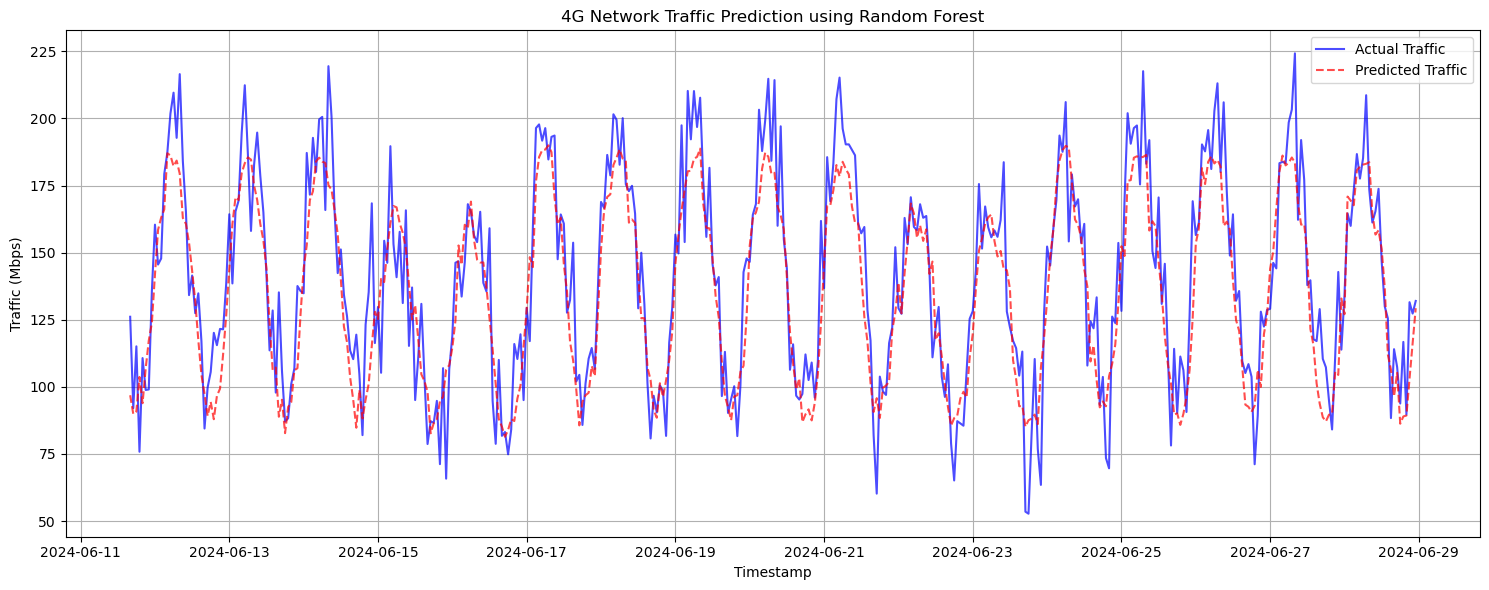

C:\Users\user\AppData\Local\Temp\ipykernel_3032\2487907444.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')


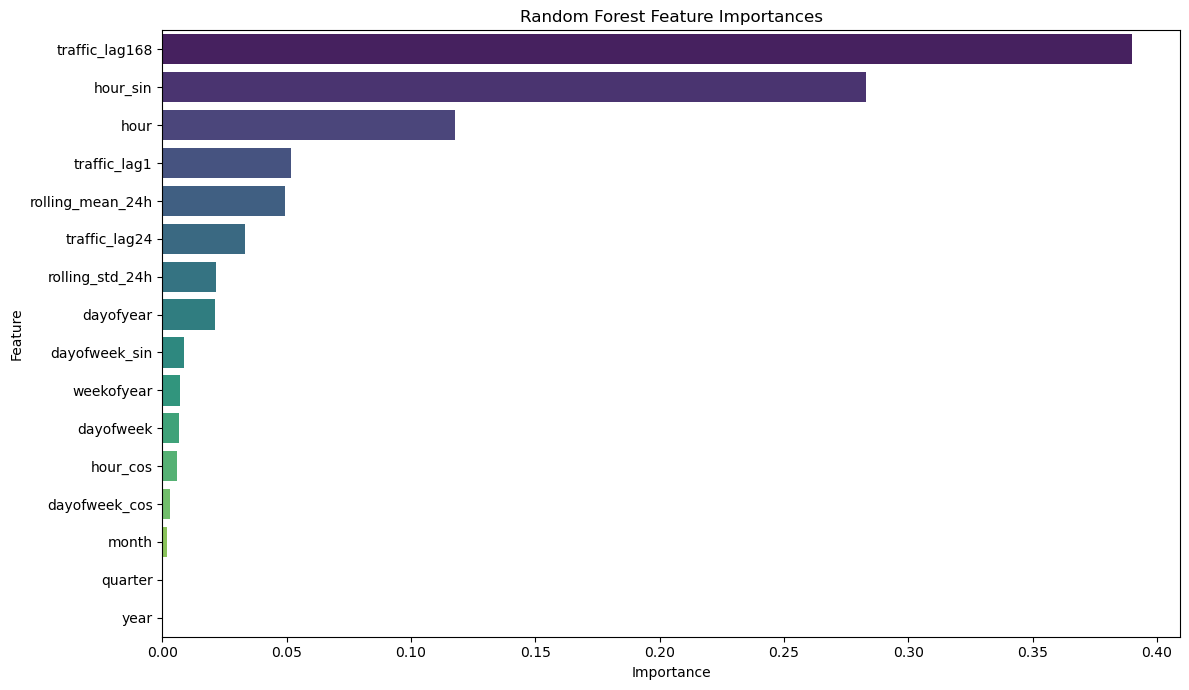

In [23]:
# --- 7. Visualize Results ---

plt.figure(figsize=(15, 6))
plt.plot(y_test.index, y_test, label='Actual Traffic', color='blue', alpha=0.7)
plt.plot(y_test.index, predictions, label='Predicted Traffic', color='red', linestyle='--', alpha=0.7)
plt.title('4G Network Traffic Prediction using Random Forest')
plt.xlabel('Timestamp')
plt.ylabel('Traffic (Mbps)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Visualize Feature Importance
plt.figure(figsize=(12, 7))
feature_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [30]:
joblib.dump(rf_model, "rf_model.pkl")

['rf_model.pkl']